# 3.0 Comparative Evaluation of Multi-Domain ViT Classifiers
**Dataset:** DemogPairs (10,800 images total, 2,160 subject-disjoint test images from 120 held-out subjects)  
**Evaluation Protocol:** Strict Subject-Disjoint Partitioning (Zero Identity Leakage)  
**Evaluated Classifiers:**
1. Support Vector Machine (`SVM` / `LinearSVC` / `RBF SVC`)
2. Logistic Regression (`LR` / `L-BFGS`)
3. Random Forest (`RF`)
4. Gaussian Naive Bayes (`GNB`)

**Feature Configurations (7 Ablation Setups):**
- Single-Domain: `vit-face`, `vit-emotion`, `vit-age`
- Dual-Domain: `vit-face-age`, `vit-emotion-age`, `vit-emotion-face`
- Tri-Domain: `vit-face-emotion-age`


In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utils as u


In [2]:
# Load all result files from results/
rpaths = [p for p in os.listdir('results') if p.endswith('.json')]
print(f'Found {len(rpaths)} result files')

results = []
for f in rpaths:
    rm = u.load_json(f'results/{f}')
    # Parse filename: demogpairs_{classifier}_{feature}_{model}.json
    parts = f.replace('.json', '').split('_')
    classifier = parts[1]  # svm, gnb, rf, lr
    feature = '_'.join(parts[2:-1])  # vit-face, vit-emotion-age, etc.
    row = {
        'Classifier': classifier.upper(),
        'Features': feature,
        'Accuracy': round(rm['test_accuracy'], 4),
        'Precision': round(rm['test_precision'], 4),
        'Recall': round(rm['test_recall'], 4),
        'F1-Score': round(rm['test_f1'], 4),
        'Latency (ms)': round(rm.get('latency_ms_per_sample', 0), 4),
        'Model Size (MB)': round(rm.get('model_size_mb', 0), 2),
    }
    results.append(row)

df = pd.DataFrame(results)
print(f'Total results: {len(df)}')
df


Found 28 result files
Total results: 28


,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
0,GNB,vit-age,0.6708,0.6691,0.6708,0.6686,0.0045,0.37
1,GNB,vit-emotion-age,0.7588,0.7597,0.7588,0.7578,0.0048,0.24
2,GNB,vit-emotion-face,0.8431,0.8437,0.8431,0.8430,0.0083,0.78
3,GNB,vit-emotion,0.7213,0.7251,0.7213,0.7199,0.0031,0.13
4,GNB,vit-face-age,0.8306,0.8347,0.8306,0.8310,0.0080,0.75
5,GNB,vit-face-emotion-age,0.8361,0.8379,0.8361,0.8364,0.0081,1.36
6,GNB,vit-face,0.8255,0.8268,0.8255,0.8250,0.0031,0.19
7,LR,vit-age,0.8148,0.8145,0.8148,0.8146,0.0028,0.06
8,LR,vit-emotion-age,0.8667,0.8668,0.8667,0.8667,0.0040,0.08
9,LR,vit-emotion-face,0.8745,0.8759,0.8745,0.8749,0.0039,0.08


## 1. Support Vector Machine (SVM)

In [3]:
svm_results = df[df['Classifier'] == 'SVM'].sort_values('Accuracy', ascending=False).reset_index(drop=True)
svm_results.insert(0, 'No', range(1, len(svm_results) + 1))
_ = u.display_table(svm_results.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,SVM,vit-face-emotion-age,0.8861,0.8871,0.8861,0.8863,4.4481,36.6
2,SVM,vit-emotion-face,0.8843,0.885,0.8843,0.8844,0.9707,15.27
3,SVM,vit-face-age,0.8755,0.8766,0.8755,0.8757,2.2581,23.48
4,SVM,vit-emotion-age,0.8625,0.8626,0.8625,0.8624,3.1451,32.76
5,SVM,vit-face,0.8616,0.8624,0.8616,0.8619,3.0653,7.56
6,SVM,vit-emotion,0.8579,0.8584,0.8579,0.858,1.8871,15.3
7,SVM,vit-age,0.8255,0.8268,0.8255,0.8258,2.0104,18.22


## 2. Gaussian Naive Bayes (GNB)

In [4]:
gnb_results = df[df['Classifier'] == 'GNB'].sort_values('Accuracy', ascending=False).reset_index(drop=True)
gnb_results.insert(0, 'No', range(1, len(gnb_results) + 1))
_ = u.display_table(gnb_results.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,GNB,vit-emotion-face,0.8431,0.8437,0.8431,0.843,0.0083,0.78
2,GNB,vit-face-emotion-age,0.8361,0.8379,0.8361,0.8364,0.0081,1.36
3,GNB,vit-face-age,0.8306,0.8347,0.8306,0.831,0.008,0.75
4,GNB,vit-face,0.8255,0.8268,0.8255,0.825,0.0031,0.19
5,GNB,vit-emotion-age,0.7588,0.7597,0.7588,0.7578,0.0048,0.24
6,GNB,vit-emotion,0.7213,0.7251,0.7213,0.7199,0.0031,0.13
7,GNB,vit-age,0.6708,0.6691,0.6708,0.6686,0.0045,0.37


## 3. Random Forest (RF)

In [5]:
rf_results = df[df['Classifier'] == 'RF'].sort_values('Accuracy', ascending=False).reset_index(drop=True)
rf_results.insert(0, 'No', range(1, len(rf_results) + 1))
_ = u.display_table(rf_results.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,RF,vit-face-emotion-age,0.85,0.8506,0.85,0.8493,0.0537,6.19
2,RF,vit-face-age,0.8486,0.8488,0.8486,0.8478,0.031,6.19
3,RF,vit-emotion-face,0.8486,0.8493,0.8486,0.8479,0.0316,8.58
4,RF,vit-face,0.8403,0.8413,0.8403,0.8403,0.0314,5.99
5,RF,vit-emotion-age,0.7731,0.7734,0.7731,0.7728,0.0392,12.35
6,RF,vit-emotion,0.7611,0.7602,0.7611,0.7603,0.0316,10.34
7,RF,vit-age,0.7181,0.7176,0.7181,0.717,0.0327,11.21


## 4. Logistic Regression (LR)

In [6]:
lr_results = df[df['Classifier'] == 'LR'].sort_values('Accuracy', ascending=False).reset_index(drop=True)
lr_results.insert(0, 'No', range(1, len(lr_results) + 1))
_ = u.display_table(lr_results.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,LR,vit-face-emotion-age,0.8866,0.8875,0.8866,0.8868,0.0054,0.11
2,LR,vit-emotion-face,0.8745,0.8759,0.8745,0.8749,0.0039,0.08
3,LR,vit-face-age,0.8741,0.8744,0.8741,0.874,0.009,0.11
4,LR,vit-emotion-age,0.8667,0.8668,0.8667,0.8667,0.004,0.08
5,LR,vit-face,0.8639,0.8646,0.8639,0.864,0.0008,0.04
6,LR,vit-emotion,0.8523,0.8535,0.8523,0.8527,0.0037,0.06
7,LR,vit-age,0.8148,0.8145,0.8148,0.8146,0.0028,0.06


## 5. All Classifiers - Ranked by Accuracy (Leaderboard)

In [7]:
all_results = df.sort_values('Accuracy', ascending=False).reset_index(drop=True)
all_results.insert(0, 'No', range(1, len(all_results) + 1))
_ = u.display_table(all_results.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,LR,vit-face-emotion-age,0.8866,0.8875,0.8866,0.8868,0.0054,0.11
2,SVM,vit-face-emotion-age,0.8861,0.8871,0.8861,0.8863,4.4481,36.6
3,SVM,vit-emotion-face,0.8843,0.885,0.8843,0.8844,0.9707,15.27
4,SVM,vit-face-age,0.8755,0.8766,0.8755,0.8757,2.2581,23.48
5,LR,vit-emotion-face,0.8745,0.8759,0.8745,0.8749,0.0039,0.08
6,LR,vit-face-age,0.8741,0.8744,0.8741,0.874,0.009,0.11
7,LR,vit-emotion-age,0.8667,0.8668,0.8667,0.8667,0.004,0.08
8,LR,vit-face,0.8639,0.8646,0.8639,0.864,0.0008,0.04
9,SVM,vit-emotion-age,0.8625,0.8626,0.8625,0.8624,3.1451,32.76
10,SVM,vit-face,0.8616,0.8624,0.8616,0.8619,3.0653,7.56


## 6. Best Classifier per Feature Configuration

In [8]:
best_per_config = df.loc[df.groupby('Features')['Accuracy'].idxmax()]
best_per_config = best_per_config.sort_values('Accuracy', ascending=False).reset_index(drop=True)
best_per_config.insert(0, 'No', range(1, len(best_per_config) + 1))
_ = u.display_table(best_per_config.to_dict('records'))


No,Classifier,Features,Accuracy,Precision,Recall,F1-Score,Latency (ms),Model Size (MB)
1,LR,vit-face-emotion-age,0.8866,0.8875,0.8866,0.8868,0.0054,0.11
2,SVM,vit-emotion-face,0.8843,0.885,0.8843,0.8844,0.9707,15.27
3,SVM,vit-face-age,0.8755,0.8766,0.8755,0.8757,2.2581,23.48
4,LR,vit-emotion-age,0.8667,0.8668,0.8667,0.8667,0.004,0.08
5,LR,vit-face,0.8639,0.8646,0.8639,0.864,0.0008,0.04
6,SVM,vit-emotion,0.8579,0.8584,0.8579,0.858,1.8871,15.3
7,SVM,vit-age,0.8255,0.8268,0.8255,0.8258,2.0104,18.22


## 7. Feature Ablation Delta (vs. Baseline `vit-face`)
Peningkatan akurasi ($\Delta 	ext{Acc}$) dan F1-Score ($\Delta 	ext{F1}$) dari penambahan domain fitur terhadap baseline `vit-face`.


In [9]:
ablation_rows = []
for clf in ['SVM', 'LR', 'RF', 'GNB']:
    sub_df = df[df['Classifier'] == clf].set_index('Features')
    if 'vit-face' in sub_df.index:
        base_acc = sub_df.loc['vit-face', 'Accuracy']
        base_f1 = sub_df.loc['vit-face', 'F1-Score']
        for feat in ['vit-age', 'vit-emotion', 'vit-face-age', 'vit-emotion-age', 'vit-emotion-face', 'vit-face-emotion-age']:
            if feat in sub_df.index:
                acc = sub_df.loc[feat, 'Accuracy']
                f1 = sub_df.loc[feat, 'F1-Score']
                ablation_rows.append({
                    'Classifier': clf,
                    'Feature Configuration': feat,
                    'Accuracy': acc,
                    'Delta Acc (%)': round((acc - base_acc) * 100, 2),
                    'F1-Score': f1,
                    'Delta F1 (%)': round((f1 - base_f1) * 100, 2)
                })

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.insert(0, 'No', range(1, len(ablation_df) + 1))
_ = u.display_table(ablation_df.to_dict('records'))


No,Classifier,Feature Configuration,Accuracy,Delta Acc (%),F1-Score,Delta F1 (%)
1,SVM,vit-age,0.8255,-3.61,0.8258,-3.61
2,SVM,vit-emotion,0.8579,-0.37,0.858,-0.39
3,SVM,vit-face-age,0.8755,1.39,0.8757,1.38
4,SVM,vit-emotion-age,0.8625,0.09,0.8624,0.05
5,SVM,vit-emotion-face,0.8843,2.27,0.8844,2.25
6,SVM,vit-face-emotion-age,0.8861,2.45,0.8863,2.44
7,LR,vit-age,0.8148,-4.91,0.8146,-4.94
8,LR,vit-emotion,0.8523,-1.16,0.8527,-1.13
9,LR,vit-face-age,0.8741,1.02,0.874,1.0
10,LR,vit-emotion-age,0.8667,0.28,0.8667,0.27


## 8. Visualizations: Accuracy Comparison & Efficiency Pareto Frontier

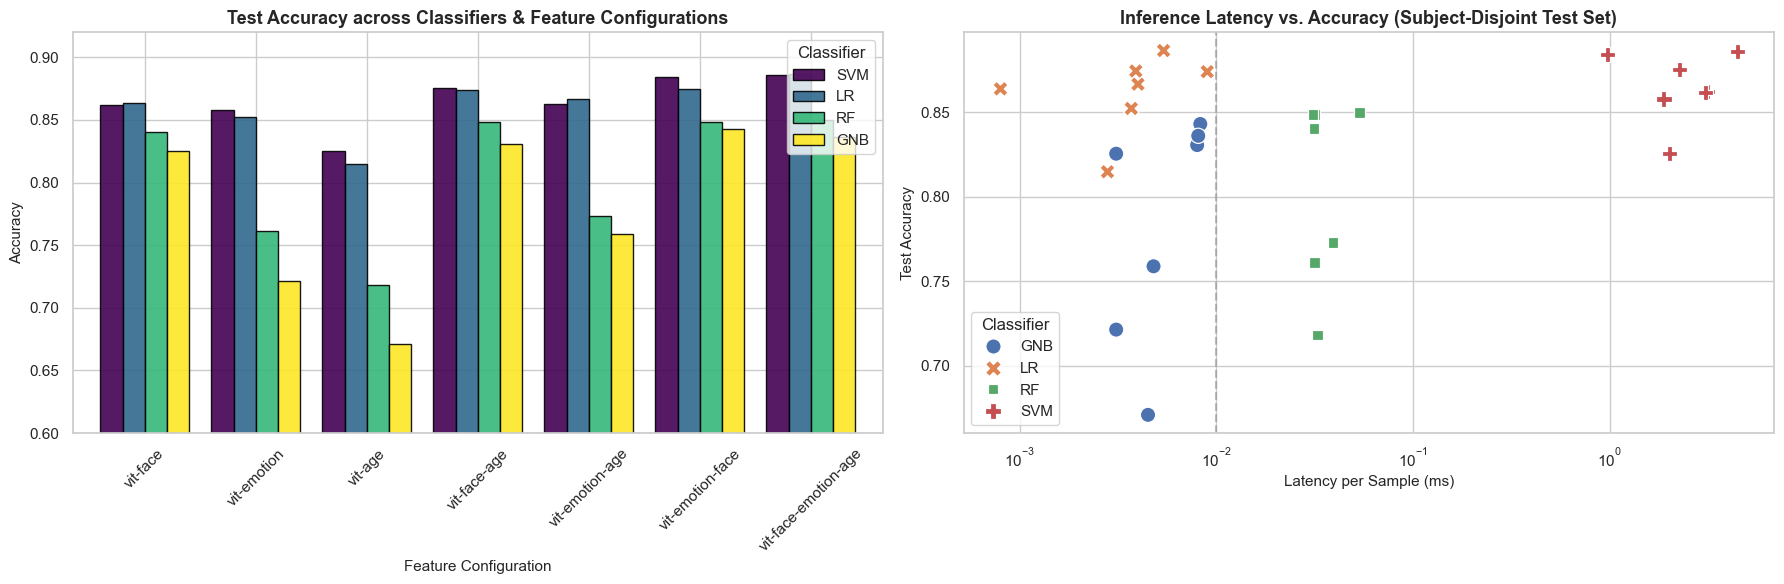

Figure saved to images/compare_accuracy_and_latency.png


In [10]:
# Set visualization style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Accuracy Comparison across Classifiers and Configurations
feat_order = ['vit-face', 'vit-emotion', 'vit-age', 'vit-face-age', 'vit-emotion-age', 'vit-emotion-face', 'vit-face-emotion-age']
clf_order = ['SVM', 'LR', 'RF', 'GNB']

pivot_acc = df.pivot(index='Features', columns='Classifier', values='Accuracy').reindex(feat_order)[clf_order]
pivot_acc.plot(kind='bar', ax=axes[0], colormap='viridis', width=0.8, edgecolor='black', alpha=0.9)
axes[0].set_title('Test Accuracy across Classifiers & Feature Configurations', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].set_xlabel('Feature Configuration', fontsize=11)
axes[0].set_ylim(0.60, 0.92)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Classifier', frameon=True)

# Plot 2: Latency vs Accuracy (Efficiency Analysis)
sns.scatterplot(
    data=df,
    x='Latency (ms)',
    y='Accuracy',
    hue='Classifier',
    style='Classifier',
    s=120,
    palette='deep',
    ax=axes[1]
)
axes[1].set_title('Inference Latency vs. Accuracy (Subject-Disjoint Test Set)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Latency per Sample (ms)', fontsize=11)
axes[1].set_ylabel('Test Accuracy', fontsize=11)
axes[1].set_xscale('log')
axes[1].axvline(0.01, color='gray', linestyle='--', alpha=0.5, label='10 µs threshold')

plt.tight_layout()
os.makedirs('images', exist_ok=True)
plot_path = 'images/compare_accuracy_and_latency.png'
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Figure saved to {plot_path}')
